In [ ]:
import pandas as pd
%pip install pytrends
from pytrends.request import TrendReq
pytrend = TrendReq(hl="es-AR", tz=180)
import matplotlib.pyplot as plt

1 ¿Cuál de los 5 conceptos saludables concentra el mayor volumen promedio de búsqueda en los últimos 5 años?

2 ¿Qué términos muestran el mayor crecimiento porcentual entre el primer año y el último año analizado?

3 ¿Existen patrones de estacionalidad marcada a lo largo del año (picos en meses específicos)?

4 ¿Qué conceptos presentan una demanda estable todo el año frente a otros con picos aislados?

5 ¿Cómo se posiciona CABA frente al resto del país en el interés relativo por estos conceptos?

In [ ]:
pytrends = TrendReq(hl="es-AR", tz=180)
conceptos = ['sin tacc', 'saludable', 'veggie', 'cafe de especialidad', 'productos organicos']

pytrends.build_payload(
    kw_list=conceptos,
    timeframe="today 5-y",
    geo="AR-C"  # Filtro exclusivo Ciudad Autónoma de Buenos Aires
)

df_caba = pytrends.interest_over_time()
df_caba = df_caba[df_caba['isPartial'] == False].drop(columns=['isPartial'])
df_caba.to_csv('../data/raw/conceptos_interes_caba.csv')

1 ¿Cuál de los 5 conceptos saludables concentra el mayor volumen promedio de búsqueda en los últimos 5 años?

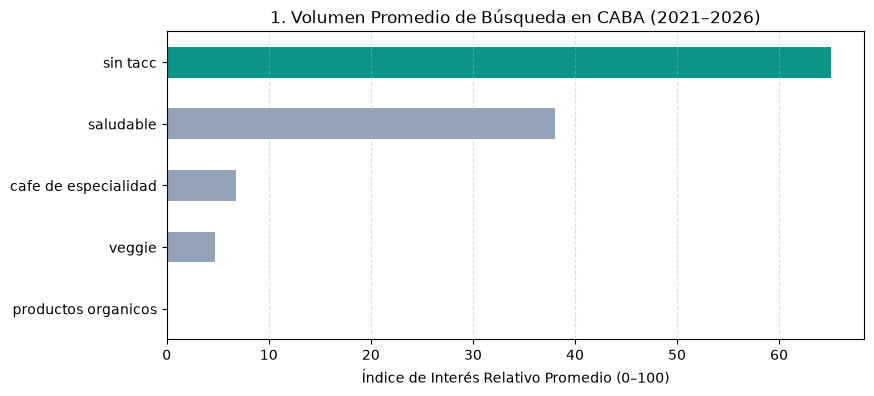

In [ ]:
import os
os.makedirs("../images", exist_ok=True)

medias = df_caba.mean().sort_values(ascending=True)
colores = ["#94A3B8"] * (len(medias) - 1) + ["#0D9488"]

medias.plot.barh(
    figsize=(9, 4),
    color=colores,
    title="1. Volumen Promedio de Búsqueda en CABA (2021–2026)",
)
plt.xlabel("Índice de Interés Relativo Promedio (0–100)")
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.savefig(
    "../images/01_liderazgo_busquedas_sin_tacc_caba.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

2 ¿Qué términos muestran el mayor crecimiento porcentual entre el primer año y el último año analizado?

Variación porcentual (Primer Año vs. Último Año):
cafe de especialidad    103.96
productos organicos      40.00
sin tacc                 22.08
saludable                 5.84
veggie                  -83.27
dtype: float64


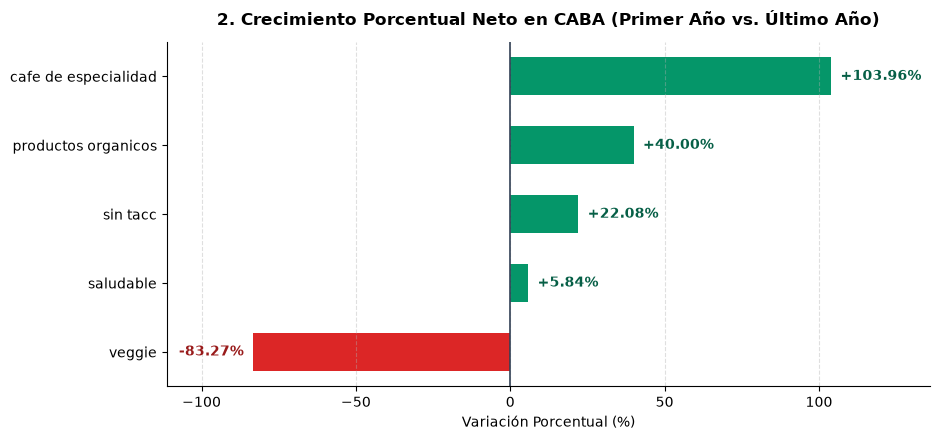

In [136]:
import os
import matplotlib.pyplot as plt
import pandas as pd

os.makedirs("../images", exist_ok=True)

# 1. Cálculo de promedios del primer año (primeras 52 sem) vs. último año (últimas 52 sem)
primer_anio = df_caba.iloc[:52].mean()
ultimo_anio = df_caba.iloc[-52:].mean()

# Variación porcentual (evitando división por cero si algún término tuviera base 0)
var_pct = ((ultimo_anio - primer_anio) / primer_anio.replace(0, float("nan")) * 100).round(2)
var_pct = var_pct.dropna().sort_values(ascending=True)

print("Variación porcentual (Primer Año vs. Último Año):")
print(var_pct.sort_values(ascending=False))

# 2. Gráfico de barras horizontales divergentes
fig, ax = plt.subplots(figsize=(9.5, 4.5))

colores = ["#DC2626" if v < 0 else "#059669" for v in var_pct.values]
bars = ax.barh(var_pct.index, var_pct.values, color=colores, height=0.55)

# Línea vertical de referencia en 0%
ax.axvline(0, color="#334155", linewidth=1.2)

# Etiquetas con el porcentaje exacto en el extremo de cada barra
for bar in bars:
  w = bar.get_width()
  offset = 3 if w >= 0 else -3
  ha = "left" if w >= 0 else "right"
  ax.text(
      w + offset,
      bar.get_y() + bar.get_height() / 2,
      f"{w:+.2f}%",
      va="center",
      ha=ha,
      fontsize=10,
      fontweight="bold",
      color="#065F46" if w >= 0 else "#991B1B",
  )

ax.set_title(
    "2. Crecimiento Porcentual Neto en CABA (Primer Año vs. Último Año)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Variación Porcentual (%)")
ax.set_xlim(var_pct.min() - 28, var_pct.max() + 32)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    "../images/02_variacion_porcentual_neta_busquedas_caba.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

3 ¿Existen patrones de estacionalidad marcada a lo largo del año (picos en meses específicos)?

Resumen de Estacionalidad Mensual en CABA:
                     Mes Pico  Valor Pico Mes Valle  Valor Valle  \
sin tacc                  Jul        70.5       Nov         58.2   
saludable                 Ago        43.3       Dic         28.8   
cafe de especialidad      Ago         9.5       Dic          3.4   
veggie                    Dic         6.2       Oct          3.7   
productos organicos       Feb         0.4       Ene          0.0   

                      Amplitud (Pico - Valle)  
sin tacc                                 12.3  
saludable                                14.5  
cafe de especialidad                      6.1  
veggie                                    2.5  
productos organicos                       0.4  


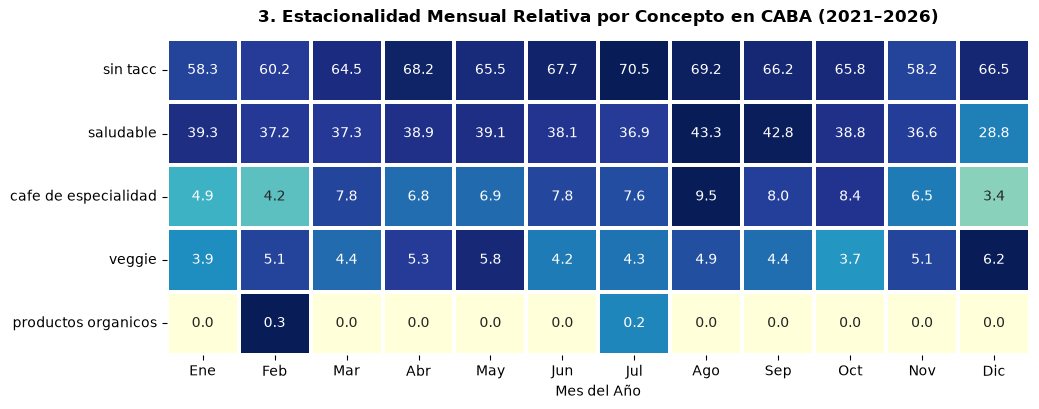

In [130]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Agrupamos por mes del año (1 a 12) y ordenamos por volumen general
orden = df_caba.mean().sort_values(ascending=False).index
mensual = df_caba.groupby(df_caba.index.month).mean().T
mensual = mensual.loc[orden]
mensual.columns = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

# Resumen automático de mes pico y mes valle por concepto
resumen_estacional = pd.DataFrame({
    'Mes Pico': mensual.idxmax(axis=1),
    'Valor Pico': mensual.max(axis=1).round(1),
    'Mes Valle': mensual.idxmin(axis=1),
    'Valor Valle': mensual.min(axis=1).round(1),
    'Amplitud (Pico - Valle)': (mensual.max(axis=1) - mensual.min(axis=1)).round(1)
})
print("Resumen de Estacionalidad Mensual en CABA:")
print(resumen_estacional)

# 2. Normalización por fila (0 a 1) solo para el color, mostrando los valores reales en cada celda
mensual_norm = mensual.div(mensual.max(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10.5, 4.2))
sns.heatmap(
    mensual_norm,
    annot=mensual,          # Imprime los promedios reales (ej. 70.5, 43.3, 9.5)
    fmt='.1f',
    cmap='YlGnBu',
    cbar=False,
    linewidths=1.5,
    linecolor='white',
    ax=ax
)

ax.set_title('3. Estacionalidad Mensual Relativa por Concepto en CABA (2021–2026)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Mes del Año')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

Resumen de Estacionalidad Mensual en CABA:
                     Mes Pico  Valor Pico Mes Valle  Valor Valle  \
sin tacc                  Jul        70.5       Nov         58.2   
saludable                 Ago        43.3       Dic         28.8   
cafe de especialidad      Ago         9.5       Dic          3.4   
veggie                    Dic         6.2       Oct          3.7   
productos organicos       Feb         0.4       Ene          0.0   

                      Amplitud (Pico - Valle)  
sin tacc                                 12.3  
saludable                                14.5  
cafe de especialidad                      6.1  
veggie                                    2.5  
productos organicos                       0.4  


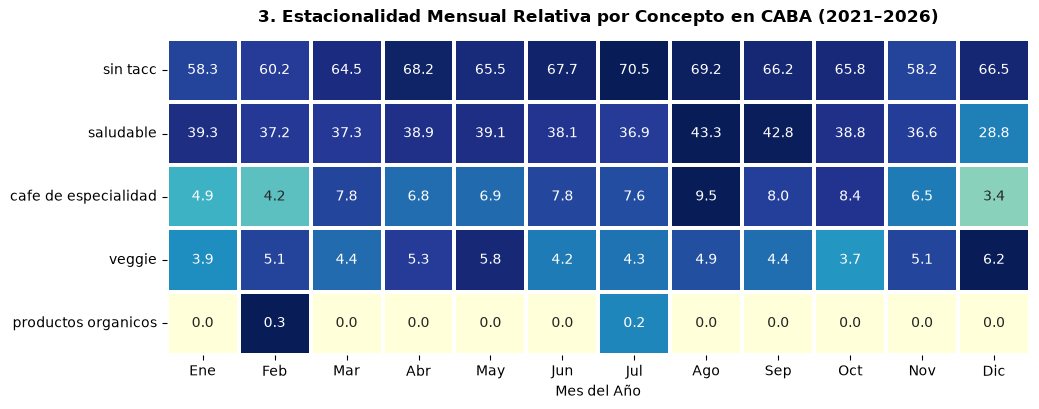

In [137]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

os.makedirs("../images", exist_ok=True)

# 1. Agrupamos por mes del año (1 a 12) y ordenamos por volumen general
orden = df_caba.mean().sort_values(ascending=False).index
mensual = df_caba.groupby(df_caba.index.month).mean().T
mensual = mensual.loc[orden]
mensual.columns = [
    "Ene",
    "Feb",
    "Mar",
    "Abr",
    "May",
    "Jun",
    "Jul",
    "Ago",
    "Sep",
    "Oct",
    "Nov",
    "Dic",
]

# Resumen automático de mes pico y mes valle por concepto
resumen_estacional = pd.DataFrame({
    "Mes Pico": mensual.idxmax(axis=1),
    "Valor Pico": mensual.max(axis=1).round(1),
    "Mes Valle": mensual.idxmin(axis=1),
    "Valor Valle": mensual.min(axis=1).round(1),
    "Amplitud (Pico - Valle)": (
        mensual.max(axis=1) - mensual.min(axis=1)
    ).round(1),
})
print("Resumen de Estacionalidad Mensual en CABA:")
print(resumen_estacional)

# 2. Normalización por fila (0 a 1) solo para el color, mostrando los valores reales en cada celda
mensual_norm = mensual.div(mensual.max(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10.5, 4.2))
sns.heatmap(
    mensual_norm,
    annot=mensual,  # Imprime los promedios reales (ej. 70.5, 43.3, 9.5)
    fmt=".1f",
    cmap="YlGnBu",
    cbar=False,
    linewidths=1.5,
    linecolor="white",
    ax=ax,
)

ax.set_title(
    "3. Estacionalidad Mensual Relativa por Concepto en CABA (2021–2026)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Mes del Año")
ax.set_ylabel("")
plt.tight_layout()

plt.savefig(
    "../images/03_estacionalidad_mensual_conceptos_caba.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

4 ¿Qué conceptos presentan una demanda estable todo el año frente a otros con picos aislados?

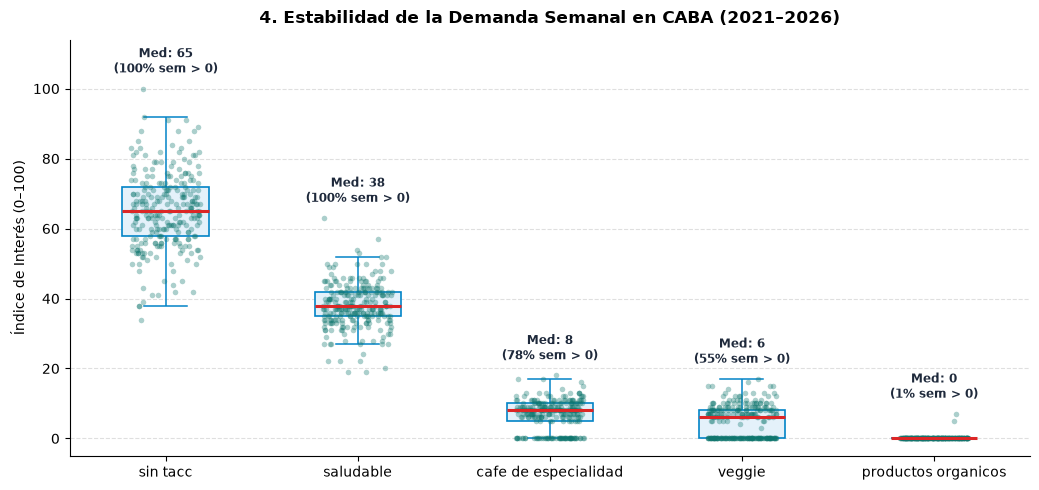

In [138]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../images", exist_ok=True)

orden = df_caba.mean().sort_values(ascending=False).index
datos = df_caba[orden]

fig, ax = plt.subplots(figsize=(10.5, 5))

# 1. Boxplot estilizado con mediana roja bien visible
sns.boxplot(
    data=datos,
    ax=ax,
    color="#E0F2FE",
    width=0.45,
    fliersize=0,
    boxprops=dict(edgecolor="#0284C7", linewidth=1.2),
    medianprops=dict(
        color="#DC2626", linewidth=2.2, zorder=4
    ),  # Mediana roja encima de los puntos
    whiskerprops=dict(color="#0284C7", linewidth=1.1),
    capprops=dict(color="#0284C7", linewidth=1.1),
)

# 2. Puntos semanales más sutiles para no tapar la caja ni la mediana
sns.stripplot(
    data=datos,
    ax=ax,
    color="#0F766E",
    size=4,
    jitter=0.18,
    alpha=0.35,
    zorder=2,
)

# 3. Anotaciones ejecutivas arriba de cada columna (Mediana y % de semanas > 0)
for i, col in enumerate(orden):
  mediana = datos[col].median()
  pct_activo = (datos[col] > 0).mean() * 100
  y_max = datos[col].max()

  ax.text(
      i,
      y_max + 3.5,
      f"Med: {mediana:.0f}\n({pct_activo:.0f}% sem > 0)",
      ha="center",
      va="bottom",
      fontsize=8.5,
      color="#1E293B",
      fontweight="bold",
  )

ax.set_ylim(-5, 114)  # Espacio extra arriba para las etiquetas y abajo para el 0
ax.set_yticks(range(0, 101, 20))
ax.set_title(
    "4. Estabilidad de la Demanda Semanal en CABA (2021–2026)",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.set_ylabel("Índice de Interés (0–100)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    "../images/04_estabilidad_demanda_semanal_caba.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()